In [1]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
data = pd.read_excel("sample data.xlsx")

In [5]:
data = pd.read_excel("sample data.xlsx")

text_cols = [f"Q{i}_CH" for i in range(1, 34) if i != 22]

data["combined_text"] = (
    data[text_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

targetvariable = "Extroversion_S"
data[targetvariable] = pd.to_numeric(
    data[targetvariable], errors="coerce"
)

# Split: 80% training / 20% testing
train, test = train_test_split(
    data,
    test_size=0.20,
    random_state=806
)

y_train = train[targetvariable]
y_test = test[targetvariable]

In [11]:
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModel.from_pretrained(model_name)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

bert_model.to(device)
bert_model.eval()

print("Using:", device)

def get_embeddings(texts):
    embeddings = []

    for i, text in enumerate(texts):
        encoded = tokenizer(
            text,
            truncation=True,
            max_length=512,
            stride=0,
            return_overflowing_tokens=True,
            return_special_tokens_mask=True,
            padding=True,
            return_tensors="pt"
        )

        token_sum = torch.zeros(
            bert_model.config.dim,
            device=device
        )
        token_count = 0

        # Process four chunks at a time
        for start in range(0, len(encoded["input_ids"]), 4):
            inputs = {
                key: encoded[key][start:start + 4].to(device)
                for key in tokenizer.model_input_names
                if key in encoded
            }

            special_mask = encoded["special_tokens_mask"][
                start:start + 4
            ].to(device)

            with torch.inference_mode():
                hidden_states = bert_model(
                    **inputs
                ).last_hidden_state

            valid_tokens = (
                inputs["attention_mask"].bool()
                & ~special_mask.bool()
            )

            token_sum += (
                hidden_states * valid_tokens.unsqueeze(-1)
            ).sum(dim=(0, 1))

            token_count += valid_tokens.sum().item()

        if token_count == 0:
            raise ValueError(
                f"No usable tokens for participant at position {i}."
            )

        embedding = token_sum / token_count
        embeddings.append(embedding.cpu().numpy())

        if (i + 1) % 10 == 0 or i + 1 == len(texts):
            print(f"Processed {i + 1}/{len(texts)} participants")

    return np.vstack(embeddings)

print("\nExtracting training embeddings...")
X_train = get_embeddings(train["combined_text"].tolist())

print("\nExtracting test embeddings...")
X_test = get_embeddings(test["combined_text"].tolist())

print("Training embedding shape:", X_train.shape)
print("Test embedding shape:", X_test.shape)

Using: cpu

Extracting training embeddings...
Processed 10/136 participants
Processed 20/136 participants
Processed 30/136 participants
Processed 40/136 participants
Processed 50/136 participants
Processed 60/136 participants
Processed 70/136 participants
Processed 80/136 participants
Processed 90/136 participants
Processed 100/136 participants
Processed 110/136 participants
Processed 120/136 participants
Processed 130/136 participants
Processed 136/136 participants

Extracting test embeddings...
Processed 10/35 participants
Processed 20/35 participants
Processed 30/35 participants
Processed 35/35 participants
Training embedding shape: (136, 768)
Test embedding shape: (35, 768)


In [12]:
model = Ridge(alpha=1.0)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())
print(f"\nTest R²: {r2_score(y_test, predictions):.3f}")
print(
    f"Model RMSE: "
    f"{np.sqrt(mean_squared_error(y_test, predictions)):.3f}"
)
print(
    f"Baseline RMSE: "
    f"{np.sqrt(mean_squared_error(y_test, baseline)):.3f}"
)

prediction_table = pd.DataFrame({
    "ID": test["ID"].to_numpy(),
    "self_report": y_test.to_numpy(),
    "predicted_score": predictions
})
print("\nExample predictions:")
print(prediction_table.head().to_string(index=False))


Test R²: 0.098
Model RMSE: 0.642
Baseline RMSE: 0.676

Example predictions:
 ID  self_report  predicted_score
156         3.00         2.313352
170         2.33         2.155904
 28         3.67         2.896776
188         3.33         3.171139
 95         2.67         2.256913


In [13]:
coefficients = pd.DataFrame({
    "dimension": np.arange(X_train.shape[1]),
    "coefficient": model.coef_
})

coefficients["absolute_coefficient"] = (
    coefficients["coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
)

print("\nTop 20 dimensions by absolute coefficient:")
print(coefficients.head(20).to_string(index=False))


Top 20 dimensions by absolute coefficient:
 dimension  coefficient  absolute_coefficient
       645     0.357681              0.357681
       681     0.346285              0.346285
       351    -0.341618              0.341618
       608     0.332207              0.332207
       333    -0.323118              0.323118
        42     0.316294              0.316294
        43    -0.306908              0.306908
        83     0.306846              0.306846
       225    -0.305475              0.305475
       210     0.297488              0.297488
       443     0.293612              0.293612
        64     0.291434              0.291434
       341    -0.286210              0.286210
       559     0.282463              0.282463
       291    -0.281923              0.281923
        54     0.280065              0.280065
       563    -0.278697              0.278697
       759    -0.273308              0.273308
       522    -0.270709              0.270709
       127     0.268928             

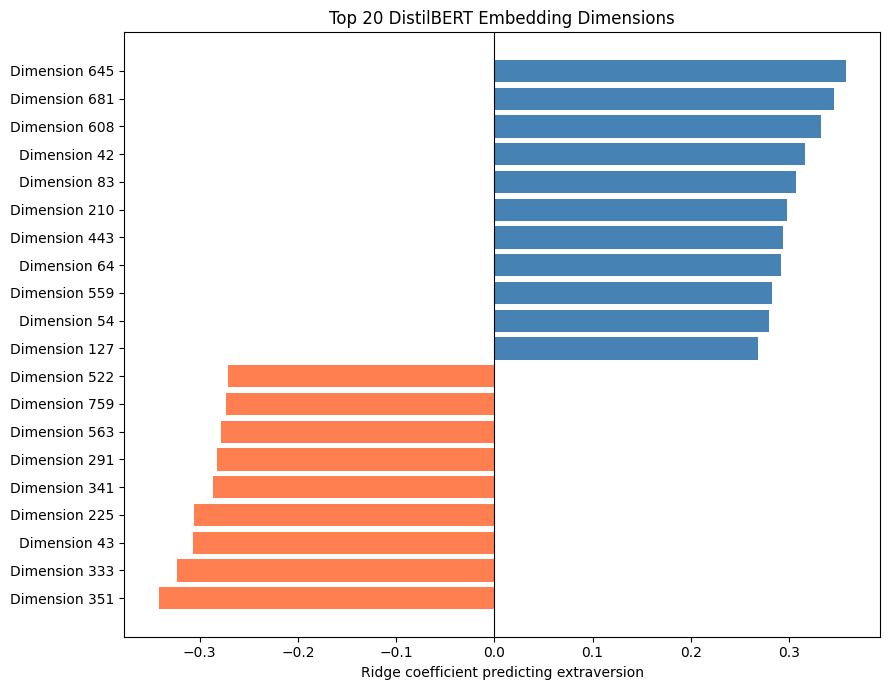

In [14]:
top_features = coefficients.head(20).sort_values("coefficient")

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["dimension"].map(lambda x: f"Dimension {x}"),
    top_features["coefficient"],
    color=np.where(
        top_features["coefficient"] > 0,
        "steelblue",
        "coral"
    )
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Ridge coefficient predicting extraversion")
plt.title("Top 20 DistilBERT Embedding Dimensions")
plt.tight_layout()
plt.show()